# LAB 05 – BÀI TẬP THỰC HÀNH PHẦN 3: BAYES NGÂY THƠ (NAÏVE BAYES)

## Thư viện

In [17]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import warnings; warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.naive_bayes import GaussianNB, CategoricalNB, BernoulliNB, MultinomialNB
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, OneHotEncoder
from sklearn.metrics import (accuracy_score, roc_auc_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

import glob, os
def find_file(patterns):
    """Tìm file CSV ở thư mục hiện tại hoặc trong /kaggle/input (khi chạy trên Kaggle)."""
    for p in patterns:
        hits = glob.glob(p) + glob.glob('/kaggle/input/**/' + p, recursive=True)
        if hits: return hits[0]
    raise FileNotFoundError('Không thấy file ' + str(patterns) + ' - hãy tải từ Kaggle và đặt cạnh notebook.')

# BÀI 1 – DỰ ĐOÁN HÀNH VI KHÁCH HÀNG (Social Network Ads)
**Mục tiêu:** dự đoán người dùng mạng xã hội có mua sản phẩm sau khi xem quảng cáo (Purchased = 1) dựa trên tuổi (Age), thu nhập ước tính (EstimatedSalary) và giới tính (Gender).
## 1.1 Nạp dữ liệu và khám phá

In [18]:
ads = pd.read_csv(find_file(['Customer_Behaviour.csv']))
print(ads.shape, '| thiếu:', int(ads.isna().sum().sum()), '| tỷ lệ mua: %.3f' % ads['Purchased'].mean())
ads.head()

(400, 5) | thiếu: 0 | tỷ lệ mua: 0.357


,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


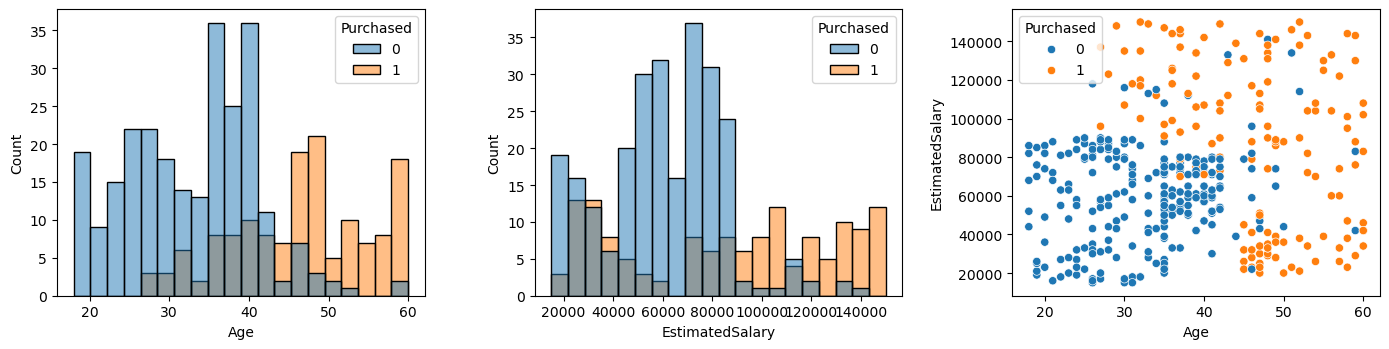

In [19]:
fig, axs = plt.subplots(1, 3, figsize=(14, 3.6))
sns.histplot(data=ads, x='Age', hue='Purchased', bins=20, ax=axs[0])
sns.histplot(data=ads, x='EstimatedSalary', hue='Purchased', bins=20, ax=axs[1])
sns.scatterplot(data=ads, x='Age', y='EstimatedSalary', hue='Purchased', ax=axs[2])
plt.tight_layout(); plt.show()

**Nhận xét khám phá dữ liệu:** Người mua tập trung ở độ tuổi từ khoảng 40 trở lên: dưới 35 tuổi hầu như chỉ có người không mua, còn từ 45 tuổi trở lên người mua chiếm đa số. Thu nhập cũng có ảnh hưởng: người có thu nhập cao (trên khoảng 100.000) mua nhiều hơn. Biểu đồ phân tán cho thấy hai nhóm mua rõ nhất là nhóm tuổi cao thu nhập cao (góc trên bên phải) và nhóm tuổi cao thu nhập thấp (góc dưới bên phải). Điều này cho thấy tuổi là yếu tố chủ đạo, thu nhập là yếu tố bổ sung.

## 1.2 Tiền xử lý và huấn luyện GaussianNB
- Bỏ cột định danh User ID.
- Gender → 0/1.
- Naive Bayes dạng Gauss không bắt buộc chuẩn hóa (mỗi đặc trưng được mô hình hóa riêng bằng một phân phối chuẩn); phần dưới thử cả hai để so sánh.
- Mô hình học, với mỗi lớp, trung bình và phương sai của từng đặc trưng (theta_, var_) cùng xác suất tiên nghiệm (class_prior_).

In [20]:
d = ads.drop(columns=[c for c in ['User ID', 'UserID'] if c in ads.columns]).copy()
if 'Gender' in d.columns: d['Gender'] = (d['Gender'].astype(str).str.lower() == 'male').astype(int)
X1, y1 = d.drop(columns='Purchased'), d['Purchased']
X_train, X_test, y_train, y_test = train_test_split(X1, y1, test_size=0.25, random_state=0, stratify=y1)

gnb = GaussianNB().fit(X_train, y_train)
print('Xác suất tiên nghiệm P(lớp):', gnb.class_prior_.round(3))
print(pd.DataFrame(gnb.theta_, columns=X1.columns, index=['lớp 0', 'lớp 1']).round(2))

Xác suất tiên nghiệm P(lớp): [0.643 0.357]
       Gender    Age  EstimatedSalary
lớp 0    0.49  32.82         59585.49
lớp 1    0.47  46.47         87345.79


**Nhận xét tham số mô hình:** Tập train có 300 mẫu và tập test 100 mẫu (tỷ lệ chia 75:25). Xác suất tiên nghiệm là 0,643 cho lớp không mua và 0,357 cho lớp mua. Giá trị trung bình học được cho thấy sự khác biệt rõ giữa hai lớp: nhóm mua có tuổi trung bình khoảng 46,5 so với 32,8 của nhóm không mua, và thu nhập trung bình khoảng 87.346 so với 59.585. Trung bình Gender của hai lớp gần như bằng nhau (0,49 và 0,47), nghĩa là giới tính hầu như không giúp phân biệt người mua với người không mua.

## 1.3 Đánh giá

Accuracy: 0.8500 | ROC AUC: 0.9462
              precision    recall  f1-score   support

           0       0.87      0.91      0.89        64
           1       0.82      0.75      0.78        36

    accuracy                           0.85       100
   macro avg       0.84      0.83      0.83       100
weighted avg       0.85      0.85      0.85       100



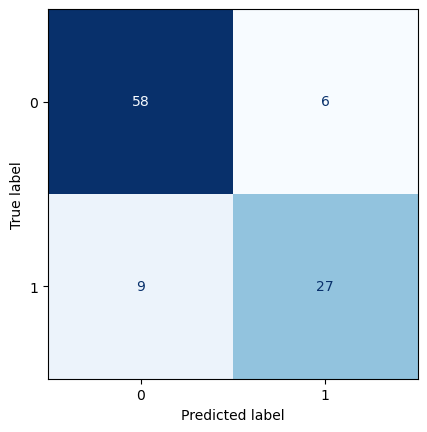

In [21]:
pred = gnb.predict(X_test); proba = gnb.predict_proba(X_test)[:, 1]
print('Accuracy: %.4f | ROC AUC: %.4f' % (accuracy_score(y_test, pred), roc_auc_score(y_test, proba)))
print(classification_report(y_test, pred))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred)).plot(cmap='Blues', colorbar=False); plt.show()

**Nhận xét kết quả đánh giá (tập test 100 mẫu):** Accuracy đạt 0,85 và ROC AUC đạt 0,9462, nghĩa là mô hình xếp hạng khả năng mua rất tốt. Theo từng lớp:
- Lớp không mua: precision 0,87, recall 0,91 (đoán đúng 58 trên 64 người).
- Lớp mua: precision 0,82, recall 0,75 (đoán đúng 27 trên 36 người, bỏ sót 9 người mua).
Mô hình thiên về dự đoán lớp không mua do lớp này chiếm nhiều hơn, nên recall của lớp mua thấp hơn. Với bài toán marketing, bỏ sót khách hàng tiềm năng làm mất doanh thu, trong khi báo nhầm chỉ tốn thêm chi phí quảng cáo, nên có thể hạ ngưỡng xác suất để tăng recall lớp mua.

## 1.4 Có/không chuẩn hóa và kiểm định chéo

In [22]:
cv = StratifiedKFold(5, shuffle=True, random_state=0)
raw = cross_val_score(GaussianNB(), X1, y1, cv=cv).mean()
sc = StandardScaler().fit(X_train)
scaled = GaussianNB().fit(sc.transform(X_train), y_train).score(sc.transform(X_test), y_test)
print('CV accuracy (dữ liệu gốc)   : %.4f' % raw)
print('Test accuracy (đã chuẩn hóa): %.4f  (so với %.4f khi chưa chuẩn hóa)' % (scaled, accuracy_score(y_test, pred)))

CV accuracy (dữ liệu gốc)   : 0.8800
Test accuracy (đã chuẩn hóa): 0.8500  (so với 0.8500 khi chưa chuẩn hóa)


**Nhận xét chuẩn hóa và kiểm định chéo:** Accuracy test không đổi (0,85) giữa dữ liệu gốc và dữ liệu đã chuẩn hóa. Điều này đúng với lý thuyết: GaussianNB mô hình hóa từng đặc trưng bằng một phân phối chuẩn riêng (trung bình và phương sai theo lớp), nên việc đổi thang đo từng đặc trưng theo phép biến đổi tuyến tính hầu như không làm thay đổi kết quả. Khác với SVM, Naive Bayes dạng Gauss không bắt buộc chuẩn hóa. Accuracy kiểm định chéo 5 lần là 0,88, cao hơn 0,85 của một lần chia test; chênh lệch 3 điểm phần trăm này là do tập test chỉ có 100 mẫu nên dao động, và con số 0,88 từ kiểm định chéo đáng tin hơn.

## 1.5 Ranh giới quyết định (Age – EstimatedSalary)
Vẽ vùng quyết định của `GaussianNB` chỉ với 2 đặc trưng liên tục để thấy ranh giới cong (do phương sai khác nhau giữa hai lớp).

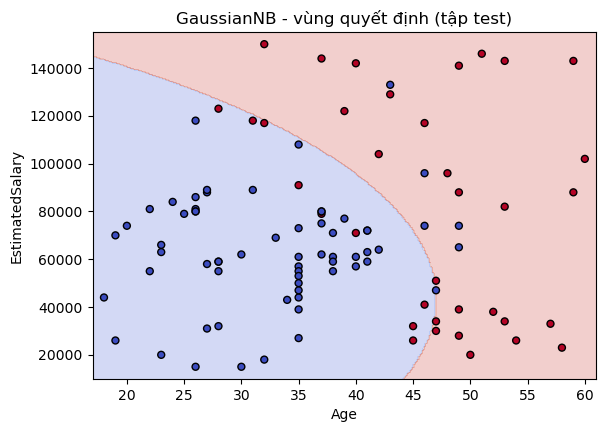

In [23]:
cols = ['Age', 'EstimatedSalary']
m2 = GaussianNB().fit(X_train[cols], y_train)
xx, yy = np.meshgrid(np.linspace(X1[cols[0]].min() - 1, X1[cols[0]].max() + 1, 300),
                     np.linspace(X1[cols[1]].min() - 5000, X1[cols[1]].max() + 5000, 300))
zz = m2.predict(pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=cols)).reshape(xx.shape)
plt.figure(figsize=(6.5, 4.5)); plt.contourf(xx, yy, zz, alpha=0.25, cmap='coolwarm')
plt.scatter(X_test[cols[0]], X_test[cols[1]], c=y_test, cmap='coolwarm', edgecolor='k', s=25)
plt.xlabel(cols[0]); plt.ylabel(cols[1]); plt.title('GaussianNB - vùng quyết định (tập test)'); plt.show()

**Nhận xét ranh giới quyết định:** Vùng màu đỏ (dự đoán mua) nằm về phía tuổi cao, và vùng màu xanh (dự đoán không mua) nằm về phía tuổi trẻ. Ranh giới là đường cong chứ không phải đường thẳng, do hai lớp có phương sai khác nhau (nhóm mua có độ phân tán tuổi và thu nhập lớn hơn), nên GaussianNB tạo ra ranh giới bậc hai. Khi thu nhập cao, ranh giới dịch về phía tuổi nhỏ hơn: người khoảng 30 đến 40 tuổi có thu nhập trên khoảng 100.000 vẫn được dự đoán là mua. Các điểm bị phân loại sai nằm gần ranh giới, chủ yếu ở độ tuổi khoảng 28 đến 47, là vùng hai lớp chồng lấn.

**Kết luận bài 1:** GaussianNB cho kết quả tốt trên bài toán này (accuracy 85%, ROC AUC 0,946, accuracy kiểm định chéo 88%) dù chỉ dùng mô hình đơn giản và không cần chuẩn hóa. Tuổi và thu nhập là hai yếu tố quyết định hành vi mua, giới tính không đóng góp. Điểm cần cải thiện là recall của lớp mua (0,75).

# BÀI 2 – PHÂN LOẠI NẤM (Mushroom)
**Mục tiêu:** phân loại nấm ăn được (e) hay độc (p) từ ~22 đặc trưng mô tả hình dạng, màu sắc, mùi... Toàn bộ đặc trưng là phân loại, nên cần mã hóa rồi dùng các biến thể Naive Bayes cho dữ liệu rời rạc.
## 2.1 Nạp dữ liệu và khám phá

In [24]:
mush = pd.read_csv(find_file(['mushrooms.csv', 'mushroom*.csv', '*mushroom*.csv']))
print(mush.shape)
print(mush['class'].value_counts(normalize=True).round(3))
print('Số giá trị khác nhau mỗi cột:'); print(mush.nunique().sort_values(ascending=False).head(8).to_string())
print('Cột có ký tự "?" (dữ liệu thiếu):', [c for c in mush.columns if (mush[c] == '?').any()])

(8124, 23)
class
e    0.518
p    0.482
Name: proportion, dtype: float64
Số giá trị khác nhau mỗi cột:
gill-color                12
cap-color                 10
spore-print-color          9
odor                       9
stalk-color-below-ring     9
stalk-color-above-ring     9
habitat                    7
cap-shape                  6
Cột có ký tự "?" (dữ liệu thiếu): ['stalk-root']


**Nhận xét dữ liệu:** Tập nấm có 8.124 mẫu, 22 đặc trưng và nhãn class, với hai lớp gần cân bằng (51,8% ăn được và 48,2% độc). Toàn bộ đặc trưng đều là phân loại (mỗi cột có từ 1 đến 12 giá trị khác nhau, nhiều nhất là gill-color với 12 giá trị). Cột stalk-root có giá trị ? biểu thị dữ liệu thiếu; ở đây được giữ như một giá trị riêng.

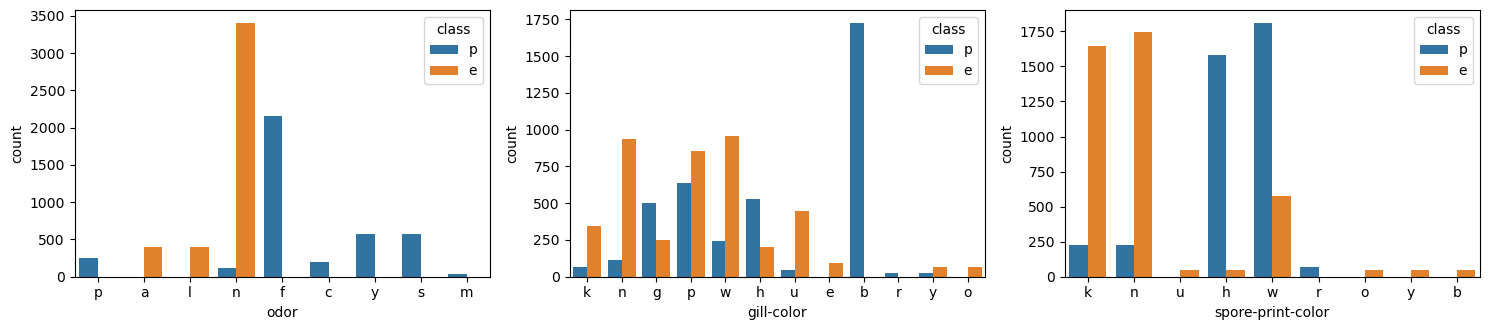

In [25]:
top = [c for c in ['odor', 'gill-color', 'spore-print-color'] if c in mush.columns][:3] or mush.columns[1:4].tolist()
fig, axs = plt.subplots(1, len(top), figsize=(5 * len(top), 3.4))
for ax, c in zip(np.atleast_1d(axs), top):
    sns.countplot(data=mush, x=c, hue='class', ax=ax)
plt.tight_layout(); plt.show()

**Nhận xét khám phá:** Một số đặc trưng gần như tự phân biệt được hai lớp:
- odor (mùi): nấm không mùi (n) gần như toàn bộ ăn được; nấm có mùi hôi (f) toàn bộ độc; các mùi p, c, y, s, m cũng đều là nấm độc, còn mùi hạnh nhân (a) và hồi (l) là nấm ăn được.
- gill-color (màu phiến nấm): màu b (vàng nhạt) gần như toàn bộ là nấm độc, rất rõ rệt.
- spore-print-color: các màu k và n chủ yếu là nấm ăn được, còn h và w có nhiều nấm độc.
Vì mỗi đặc trưng riêng lẻ đã có sức phân biệt mạnh nên Naive Bayes dự kiến cho kết quả tốt.

## 2.2 Tiền xử lý
- Nhãn: p (độc) = 1, e (ăn được) = 0 → lớp 1 là lớp cần phát hiện.
- Ký tự ? (thiếu, ở stalk-root) được giữ như một giá trị riêng của cột (là thông tin hợp lệ trong dữ liệu gốc).
- Hai cách mã hóa:
  - Ordinal (mỗi giá trị → số nguyên 0..k−1) dành cho CategoricalNB – mô hình tự học P(giá trị | lớp) cho từng cột, nên số nguyên chỉ là chỉ số, không mang ý nghĩa thứ tự.
  - One-Hot (mỗi giá trị → cột 0/1) dành cho BernoulliNB và MultinomialNB (yêu cầu đặc trưng không âm).
- Bộ mã hóa học danh sách giá trị trên toàn bộ X (không dùng nhãn nên không rò rỉ) để tránh gặp giá trị lạ ở tập test.

In [26]:
y2 = (mush['class'] == 'p').astype(int)
X2 = mush.drop(columns='class')
ord_enc = OrdinalEncoder().fit(X2)
X_ord = pd.DataFrame(ord_enc.transform(X2).astype(int), columns=X2.columns)
n_cat = [len(c) for c in ord_enc.categories_]
ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False).fit(X2)
X_ohe = ohe.transform(X2)
print('Ordinal:', X_ord.shape, '| One-Hot:', X_ohe.shape)

idx_tr, idx_te = train_test_split(np.arange(len(X2)), test_size=0.2, random_state=42, stratify=y2)
ytr, yte = y2.iloc[idx_tr], y2.iloc[idx_te]

Ordinal: (8124, 22) | One-Hot: (8124, 117)


**Nhận xét mã hóa:** Sau mã hóa, dữ liệu ordinal có 22 cột (mỗi giá trị là một chỉ số nguyên) dùng cho CategoricalNB, và dữ liệu one-hot có 117 cột nhị phân dùng cho BernoulliNB và MultinomialNB. Việc dùng hai cách mã hóa khác nhau cho phép so sánh công bằng ba biến thể Naive Bayes trên cùng dữ liệu.

## 2.3 Huấn luyện và so sánh 3 mô hình

In [27]:
models = {
    'CategoricalNB (ordinal)': (CategoricalNB(min_categories=n_cat), X_ord.values),
    'BernoulliNB (one-hot)':   (BernoulliNB(), X_ohe),
    'MultinomialNB (one-hot)': (MultinomialNB(), X_ohe),
}
rows, preds = [], {}
for name, (clf, Xm) in models.items():
    clf.fit(Xm[idx_tr], ytr); p = clf.predict(Xm[idx_te]); preds[name] = p
    tn, fp, fn, tp = confusion_matrix(yte, p).ravel()
    rows.append({'Mô hình': name, 'Accuracy': accuracy_score(yte, p),
                 'ROC AUC': roc_auc_score(yte, clf.predict_proba(Xm[idx_te])[:, 1]),
                 'Độc bị đoán là ăn được (FN)': fn, 'Ăn được bị đoán là độc (FP)': fp})
pd.DataFrame(rows).round(4)

,Mô hình,Accuracy,ROC AUC,Độc bị đoán là ăn được (FN),Ăn được bị đoán là độc (FP)
0,CategoricalNB (ordinal),0.9458,0.9972,81,7
1,BernoulliNB (one-hot),0.9329,0.9954,96,13
2,MultinomialNB (one-hot),0.9458,0.9972,81,7


**Nhận xét so sánh ba mô hình (tập test 1.625 mẫu):**

| Mô hình | Accuracy | ROC AUC | Độc bị đoán là ăn được (FN) | Ăn được bị đoán là độc (FP) |
|---|---|---|---|---|
| CategoricalNB (ordinal) | 0,9458 | 0,9972 | 81 | 7 |
| BernoulliNB (one-hot) | 0,9329 | 0,9954 | 96 | 13 |
| MultinomialNB (one-hot) | 0,9458 | 0,9972 | 81 | 7 |

- CategoricalNB và MultinomialNB cho kết quả y hệt nhau. Lý do là cả hai đều ước lượng tần suất của từng giá trị theo lớp có làm trơn Laplace, và với dữ liệu one-hot thì MultinomialNB thực chất đếm số lần xuất hiện của từng giá trị, nên hai mô hình gần như tương đương về mặt toán học.
- BernoulliNB kém hơn một chút (accuracy 0,9329). Một lý do có thể là mô hình này tính cả việc một giá trị không xuất hiện (cột one-hot bằng 0) như một bằng chứng, trong khi các cột one-hot của cùng một đặc trưng loại trừ lẫn nhau nên vi phạm giả định độc lập nặng hơn.
- ROC AUC của cả ba mô hình đều rất cao (từ 0,995 đến 0,997), nghĩa là mô hình xếp hạng nấm độc và nấm ăn được gần như hoàn hảo; phần accuracy thấp hơn 100% chủ yếu do ngưỡng quyết định 0,5 chưa phù hợp.

Mô hình tốt nhất theo accuracy: CategoricalNB (ordinal)
              precision    recall  f1-score   support

 ăn được (e)       0.91      0.99      0.95       842
     độc (p)       0.99      0.90      0.94       783

    accuracy                           0.95      1625
   macro avg       0.95      0.94      0.95      1625
weighted avg       0.95      0.95      0.95      1625



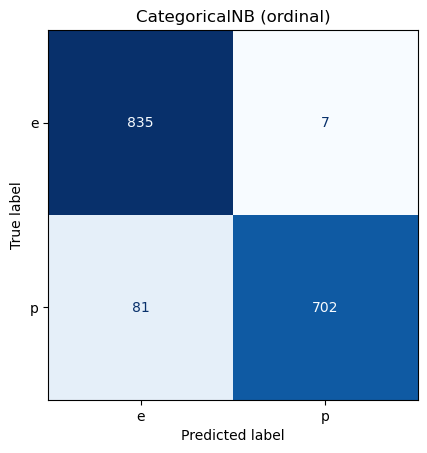

In [28]:
best = max(models, key=lambda k: accuracy_score(yte, preds[k]))
print('Mô hình tốt nhất theo accuracy:', best)
print(classification_report(yte, preds[best], target_names=['ăn được (e)', 'độc (p)']))
ConfusionMatrixDisplay(confusion_matrix(yte, preds[best]), display_labels=['e', 'p']).plot(cmap='Blues', colorbar=False)
plt.title(best); plt.show()

**Nhận xét mô hình tốt nhất (CategoricalNB):**
- Accuracy 0,95 với độ chính xác của lớp độc là 0,99 (chỉ 7 nấm ăn được bị báo nhầm là độc) và recall của lớp độc là 0,90.
- Vấn đề nghiêm trọng là 81 trên 783 cây nấm độc (khoảng 10,3%) bị đoán nhầm là ăn được. Đây là loại sai lầm nguy hiểm nhất vì có thể gây ngộ độc, trong khi báo nhầm nấm ăn được thành độc chỉ gây lãng phí. Với bài toán an toàn thực phẩm, accuracy 94,6% là chưa chấp nhận được.
- Vì ROC AUC rất cao (0,997), có thể giảm số nấm độc bị bỏ sót bằng cách hạ ngưỡng xác suất của lớp độc (ví dụ dưới 0,5) để chấp nhận thêm báo nhầm đổi lấy ít bỏ sót hơn.
- Nguyên nhân Naive Bayes chưa đạt gần như tuyệt đối là giả định độc lập có điều kiện không đúng với dữ liệu này: nhiều đặc trưng của nấm tương quan chặt chẽ với nhau (ví dụ stalk-color-above-ring và stalk-color-below-ring), khiến bằng chứng bị tính lặp. Các mô hình cây quyết định thường đạt độ chính xác gần 100% trên bộ dữ liệu này vì chúng có thể kết hợp luật theo odor và các đặc trưng khác.

## 2.4 Đặc trưng nào phân biệt nấm độc nhất?
Với CategoricalNB, dùng chênh lệch log-xác suất giữa hai lớp của từng giá trị để tìm các (đặc trưng = giá trị) nghiêng mạnh về nấm độc hoặc nấm ăn được.

In [29]:
cnb = models['CategoricalNB (ordinal)'][0]
rows = []
for j, col in enumerate(X2.columns):
    lp = cnb.feature_log_prob_[j]                      # (số lớp, số giá trị)
    for k, val in enumerate(ord_enc.categories_[j]):
        rows.append({'đặc trưng': col, 'giá trị': val, 'log P(v|độc) - log P(v|ăn được)': lp[1, k] - lp[0, k]})
d = pd.DataFrame(rows)
print('Nghiêng mạnh về NẤM ĐỘC:');      print(d.nlargest(8, d.columns[-1]).round(2).to_string(index=False))
print('\nNghiêng mạnh về ĂN ĐƯỢC:');   print(d.nsmallest(8, d.columns[-1]).round(2).to_string(index=False))

Nghiêng mạnh về NẤM ĐỘC:
             đặc trưng giá trị  log P(v|độc) - log P(v|ăn được)
                  odor       f                             7.54
            gill-color       b                             7.29
             ring-type       l                             7.03
                  odor       y                             6.20
                  odor       s                             6.18
stalk-color-above-ring       b                             5.94
stalk-color-below-ring       b                             5.94
                  odor       p                             5.34

Nghiêng mạnh về ĂN ĐƯỢC:
             đặc trưng giá trị  log P(v|độc) - log P(v|ăn được)
stalk-color-below-ring       g                            -6.08
stalk-color-above-ring       g                            -6.07
            population       n                            -5.74
                  odor       l                            -5.70
                  odor       a                       

**Nhận xét các đặc trưng phân biệt mạnh nhất:** Chênh lệch log-xác suất lớn cho biết giá trị đó xuất hiện ở nấm độc nhiều hơn rất nhiều so với nấm ăn được (giá trị dương) hoặc ngược lại (giá trị âm).
- Nghiêng mạnh về nấm độc: odor = f (mùi hôi, 7,54), gill-color = b (vàng nhạt, 7,29), ring-type = l (vòng lớn, 7,03), odor = y (mùi tanh, 6,20), odor = s (mùi cay, 6,18), màu cuống phía trên và dưới vòng = b (5,94) và odor = p (mùi hăng, 5,34). Mùi là nhóm đặc trưng nổi bật nhất, xuất hiện 4 lần trong danh sách.
- Nghiêng mạnh về nấm ăn được: màu cuống phía trên và dưới vòng = g (xám, khoảng -6,07), population = n (số lượng nhiều, -5,74), odor = l (mùi hồi, -5,70), odor = a (mùi hạnh nhân, -5,69), population = a (rất nhiều, -5,65), habitat = w (môi trường rác thải, -4,99) và stalk-root = r (có rễ, -4,96).
- Kết quả này khớp với biểu đồ khám phá: odor và gill-color là các đặc trưng có sức phân biệt cao nhất. Lưu ý các giá trị hiếm có thể có tỷ số lớn do làm trơn Laplace khi chỉ xuất hiện ở một lớp với số lượng nhỏ, nên cần đọc cùng với tần suất xuất hiện của giá trị đó.

**Kết luận bài 2:** Naive Bayes phân loại nấm với accuracy khoảng 94,6% và ROC AUC khoảng 0,997 chỉ bằng việc đếm tần suất, huấn luyện gần như tức thời. CategoricalNB và MultinomialNB là hai lựa chọn tốt nhất, BernoulliNB thấp hơn một chút. Tuy nhiên với tỷ lệ bỏ sót nấm độc khoảng 10%, mô hình này chưa đủ an toàn nếu dùng độc lập; cần hạ ngưỡng quyết định hoặc dùng mô hình mạnh hơn như Random Forest.

### Nhận xét tổng hợp phần 3

| Tiêu chí | Hành vi khách hàng | Phân loại nấm |
|---|---|---|
| Loại đặc trưng | Liên tục (Age, EstimatedSalary) và Gender | Toàn bộ phân loại (22 đặc trưng) |
| Mô hình dùng | GaussianNB | CategoricalNB, BernoulliNB, MultinomialNB |
| Cân bằng lớp | 64,3% / 35,7% | 51,8% / 48,2% |
| Accuracy test | 0,85 | 0,9458 (tốt nhất) |
| ROC AUC test | 0,9462 | 0,9972 |
| Điểm yếu chính | Recall lớp mua 0,75 | 81 nấm độc bị đoán nhầm là ăn được |

Rút ra:
- (1) Phải chọn đúng biến thể Naive Bayes theo kiểu dữ liệu: Gaussian cho đặc trưng liên tục, Categorical hoặc Multinomial cho đặc trưng rời rạc.
- (2) Naive Bayes đơn giản, nhanh và cho ROC AUC cao ngay cả khi giả định độc lập không hoàn toàn đúng, nhưng accuracy tại ngưỡng 0,5 bị ảnh hưởng khi các đặc trưng tương quan mạnh.
- (3) Ở các bài toán mà hai loại sai lầm có hậu quả khác nhau (bỏ sót nấm độc, bỏ sót khách hàng mua), cần theo dõi recall của lớp quan trọng và điều chỉnh ngưỡng quyết định thay vì chỉ nhìn accuracy.